# 05 — Approximate Quantum Compilation with Tensor Networks (`qiskit-addon-aqc-tensor`)

**Approximate quantum compilation (AQC)** replaces a deep circuit with a shallower *parametrized* circuit. The new circuit prepares approximately the same state. `qiskit-addon-aqc-tensor` uses **tensor-network simulation** for this task:

* The target state is stored as a matrix product state (MPS, defined in Section 1).
* A classical optimizer tunes the parameters of a shallow **ansatz** (a parametrized circuit template). The goal is maximum fidelity with the target MPS.
* The cost of MPS simulation grows with the *entanglement* of the state, not exponentially with the number of qubits. So the classical step works for systems much larger than a statevector simulation allows, as long as the entanglement stays low.

The main use case, shown here, is **Trotterized time evolution**. A Trotter circuit approximates $e^{-iHt}$ by a sequence of short evolutions under the individual terms of $H$. A deep Trotter circuit (many small time steps) is simulated classically as an MPS. It is then compressed into an ansatz. The structure of the ansatz comes from a *shallow* Trotter circuit with only a few steps.

**Based on**

* the AQC-Tensor getting-started tutorial [[1]](https://qiskit.github.io/qiskit-addon-aqc-tensor/tutorials/01_initial_state_aqc.html),
* the IBM Quantum tutorial on AQC for time-evolution circuits [[2]](https://quantum.cloud.ibm.com/docs/en/tutorials/approximate-quantum-compilation-for-time-evolution).

Both tutorials use larger systems and build the circuits with `qiskit-addon-utils`. Here we use a 10-qubit chain and build the circuits with Qiskit only.

Installation:

```bash
pip install "qiskit-addon-aqc-tensor[quimb-jax]"
```

The `[quimb-jax]` extra installs three packages:

* quimb, a tensor-network simulator,
* `qiskit-quimb`, which converts Qiskit gates to quimb gates,
* JAX, which computes the gradient of the objective by automatic differentiation.

The system is a 10-qubit XXZ chain. At this size we can check every result against an exact statevector. The notebook runs on a CPU in about one minute.

In [1]:
import time
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import quimb.tensor as qtn
from scipy.optimize import minimize
from scipy.sparse.linalg import expm_multiply

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.synthesis import SuzukiTrotter

import qiskit, qiskit_addon_aqc_tensor
from qiskit_addon_aqc_tensor import generate_ansatz_from_circuit
from qiskit_addon_aqc_tensor.objective import MaximizeStateFidelity
from qiskit_addon_aqc_tensor.simulation import compute_overlap, tensornetwork_from_circuit
from qiskit_addon_aqc_tensor.simulation.quimb import QuimbSimulator

print("qiskit", qiskit.__version__)
print("qiskit-addon-aqc-tensor", qiskit_addon_aqc_tensor.__version__)
print("quimb", qtn.__name__, __import__("quimb").__version__)

qiskit 2.5.2
qiskit-addon-aqc-tensor 0.3.1
quimb quimb.tensor 1.11.2


## 1. Background: tensor networks, MPS and bond dimension

A general $n$-qubit state $|\psi\rangle = \sum_{s_1\ldots s_n} c_{s_1\ldots s_n}|s_1\ldots s_n\rangle$ has $2^n$ amplitudes. A **matrix product state** factorizes the amplitude tensor into a chain of small tensors, one per qubit:

$$
c_{s_1 s_2 \ldots s_n} = A^{[1]s_1}\, A^{[2]s_2} \cdots A^{[n]s_n},
$$

where each $A^{[k]s_k}$ is a $\chi_{k-1}\times\chi_k$ matrix. The internal indices that connect neighboring tensors are the **bonds**. Their size $\chi$ is the **bond dimension**.

* The bond dimension across a cut limits the entanglement across it: $S \le \log_2 \chi$, where $S$ is the entanglement entropy. A product state has $\chi=1$. An arbitrary state needs $\chi = 2^{n/2}$ in the middle of the chain.
* Memory scales as $O(n\,\chi^2)$ and cost as $O(n\,\chi^3)$. Both are *linear in $n$* for bounded $\chi$.
* A two-qubit gate increases the bond dimension. A singular value decomposition (SVD) then **truncates** small singular values. The parameters `cutoff` and `max_bond` control this step. Truncation is the only approximation in MPS simulation.

Short-time dynamics of a 1D chain that starts in a product state builds up entanglement slowly. So an MPS with moderate $\chi$ represents the state accurately. AQC-Tensor uses this property:

* The **target** is the MPS of a deep, accurate Trotter circuit.
* The **ansatz** is optimized against the target. The gradients come from automatic differentiation through the tensor-network contraction.

## 2. The model: XXZ chain and Trotter circuits

We use the 1D XXZ Heisenberg model with open boundaries:

$$
H = J\sum_{i=0}^{L-2}\left(X_iX_{i+1} + Y_iY_{i+1} + \Delta\, Z_iZ_{i+1}\right).
$$

The initial state is the Néel state $|0101\ldots\rangle$, with alternating spins. The tutorials [[1]](https://qiskit.github.io/qiskit-addon-aqc-tensor/tutorials/01_initial_state_aqc.html), [[2]](https://quantum.cloud.ibm.com/docs/en/tutorials/approximate-quantum-compilation-for-time-evolution) build the Hamiltonian and the Trotter circuit with `qiskit-addon-utils`. That package is not installed here. We use `SparsePauliOp` and `PauliEvolutionGate` [[4]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.PauliEvolutionGate) with `SuzukiTrotter` [[5]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.synthesis.SuzukiTrotter) instead. This gives the same brick-wall circuit structure.

In [2]:
L = 10          # number of qubits
J, Delta = 1.0, 0.5
evolution_time = 2.0

# Order the terms as (all even bonds), (all odd bonds) so that the Trotter circuit
# has the usual brick-wall structure (SuzukiTrotter preserves the term order).
terms = []
for parity in (0, 1):
    for i in range(parity, L - 1, 2):
        for p, coeff in (("X", J), ("Y", J), ("Z", J * Delta)):
            terms.append((p + p, [i, i + 1], coeff))
hamiltonian = SparsePauliOp.from_sparse_list(terms, num_qubits=L)

initial_state = QuantumCircuit(L)
for q in range(1, L, 2):
    initial_state.x(q)  # Néel state

BASIS = ["rz", "rx", "ry", "x", "rxx", "ryy", "rzz"]

def trotter_circuit(t, steps):
    # Initial state followed by `steps` second-order Trotter steps of exp(-iHt).
    qc = initial_state.copy()
    qc.append(PauliEvolutionGate(hamiltonian, time=t, synthesis=SuzukiTrotter(order=2, reps=steps)), range(L))
    return transpile(qc, basis_gates=BASIS, optimization_level=0)

print(hamiltonian.num_qubits, 'qubits,', len(hamiltonian), 'Pauli terms')

10 qubits, 27 Pauli terms


We build two Trotter circuits for the same evolution time $t=2$:

* A **deep** circuit with 40 Trotter steps. It is accurate, but too deep to run well on noisy hardware. We only simulate it classically, as an MPS, to get the *target state*.
* A **shallow** circuit with 4 Trotter steps. It is short enough for hardware, but its Trotter error is large. Its *structure* defines the AQC ansatz.

We also compute the exact state $e^{-iHt}|\psi_0\rangle$ as a reference. This is possible because $L=10$.

In [3]:
deep_steps, shallow_steps = 40, 4
deep_circuit = trotter_circuit(evolution_time, deep_steps)
shallow_circuit = trotter_circuit(evolution_time, shallow_steps)

def two_qubit_depth(qc):
    return qc.depth(lambda inst: inst.operation.num_qubits == 2)

for name, qc in [("deep", deep_circuit), ("shallow", shallow_circuit)]:
    print(f"{name:8s} steps={deep_steps if name=='deep' else shallow_steps:3d}  "
          f"2q-depth={two_qubit_depth(qc):5d}  ops={dict(qc.count_ops())}")

# Exact reference state
psi0 = Statevector(initial_state).data
exact_state = expm_multiply(-1j * evolution_time * hamiltonian.to_matrix(sparse=True), psi0)

def fidelity_with_exact(qc):
    return abs(np.vdot(exact_state, Statevector(qc).data)) ** 2

print("\nFidelity with exact state:")
print(f"  deep    ({deep_steps} steps): {fidelity_with_exact(deep_circuit):.5f}")
print(f"  shallow ({shallow_steps} steps):  {fidelity_with_exact(shallow_circuit):.5f}")

deep     steps= 40  2q-depth=  480  ops={'rxx': 720, 'ryy': 720, 'rzz': 680, 'x': 5}
shallow  steps=  4  2q-depth=   48  ops={'rxx': 72, 'ryy': 72, 'rzz': 68, 'x': 5}

Fidelity with exact state:
  deep    (40 steps): 0.99993
  shallow (4 steps):  0.38160


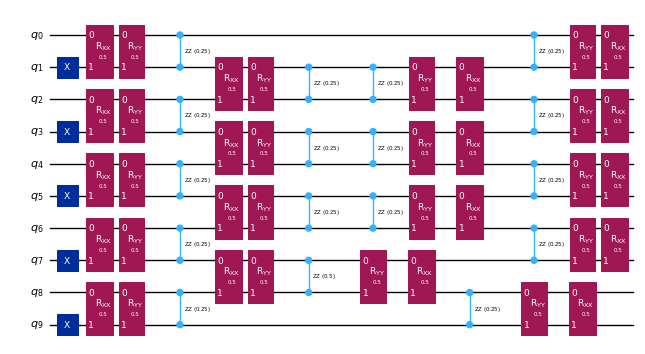

In [4]:
# One Trotter step (preceded by the Neel-state preparation)
trotter_circuit(evolution_time / shallow_steps, 1).draw("mpl", fold=-1, scale=0.5)

*(Above: the Néel preparation followed by one second-order Trotter step. This is one layer of the shallow circuit.)*

## 3. Tensor-network simulator settings

`QuimbSimulator` [[6]](https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/simulation-quimb.html) tells AQC-Tensor how to build quimb circuits. We use these settings:

* quimb's `CircuitMPS` [[7]](https://quimb.readthedocs.io/en/latest/autoapi/quimb/tensor/circuit/mps/index.html): eager MPS simulation with SVD truncation at `cutoff=1e-8`,
* JAX as the automatic-differentiation backend for the gradient of the objective.

Other options exist. `quimb.tensor.Circuit` performs lazy, exact contraction. `autodiff_backend="explicit"` selects the original AQC-Tensor gradient algorithm for `CircuitMPS`.

We then simulate the deep circuit with `tensornetwork_from_circuit` [[8]](https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/simulation.html) to obtain the **target MPS**.

In [5]:
simulator_settings = QuimbSimulator(partial(qtn.CircuitMPS, cutoff=1e-8), autodiff_backend="jax")

t0 = time.perf_counter()
target_mps = tensornetwork_from_circuit(deep_circuit, simulator_settings)
print(f"Target MPS built in {time.perf_counter() - t0:.1f} s")
print("type:", type(target_mps).__name__)
print("bond dimensions:", target_mps.psi.bond_sizes())
print(f"max bond dimension: {target_mps.psi.max_bond()}  (exact would allow up to 2^(L/2) = {2**(L//2)})")

# quimb orders qubit 0 as the most significant bit; Qiskit as the least significant
target_dense = np.squeeze(target_mps.psi.to_dense()).reshape([2] * L).transpose(range(L - 1, -1, -1)).ravel()
print(f"fidelity(target MPS, exact) = {abs(np.vdot(exact_state, target_dense))**2:.5f}")

Target MPS built in 0.8 s
type: CircuitMPS
bond dimensions: [2, 4, 8, 16, 32, 16, 8, 4, 2]
max bond dimension: 32  (exact would allow up to 2^(L/2) = 32)
fidelity(target MPS, exact) = 0.99992


### Required bond dimension

We compress the target MPS to a maximum bond dimension $\chi_{\max}$. Then we measure the fidelity with the untruncated MPS. The fidelity rises quickly with $\chi$. At $\chi_{\max}=16$ it is already 0.970, and at $\chi_{\max}=24$ it is 0.999. An arbitrary state would need $2^{L/2}=32$. For longer chains, $2^{L/2}$ grows exponentially, so the saving from a small $\chi$ becomes much larger.

{1: 0.02245, 2: 0.17218, 4: 0.43999, 8: 0.75971, 12: 0.89458, 16: 0.97, 24: 0.99876, 32: 1.0}


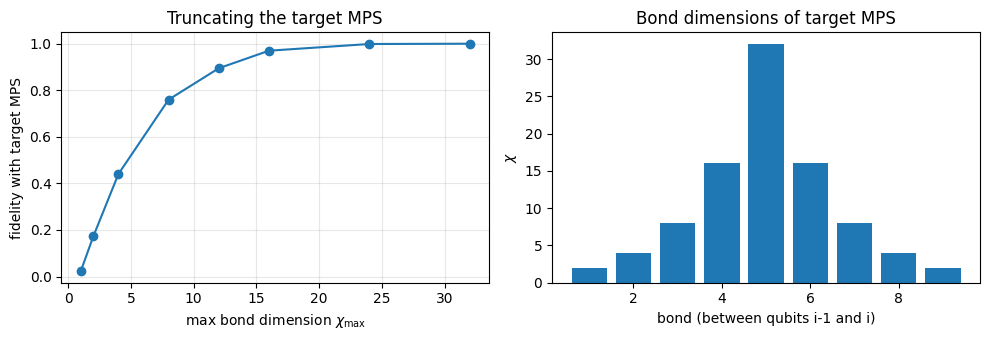

In [6]:
chis = [1, 2, 4, 8, 12, 16, 24, 32]
fids = []
for chi in chis:
    psi_c = target_mps.psi.copy()
    psi_c.compress(max_bond=chi, cutoff=0.0)
    psi_c /= psi_c.norm()
    fids.append(abs(target_mps.psi.H @ psi_c) ** 2)
print({chi: round(float(f), 5) for chi, f in zip(chis, fids)})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(chis, fids, "o-")
ax[0].set(xlabel=r"max bond dimension $\chi_{\max}$", ylabel="fidelity with target MPS", title="Truncating the target MPS")
ax[0].grid(alpha=0.3)
ax[1].bar(range(1, L), target_mps.psi.bond_sizes())
ax[1].set(xlabel="bond (between qubits i-1 and i)", ylabel=r"$\chi$", title="Bond dimensions of target MPS")
plt.tight_layout(); plt.show()

## 4. Ansatz from the shallow circuit

`generate_ansatz_from_circuit` [[9]](https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/ansatz_generation.html) reads the two-qubit connectivity of the shallow circuit. It replaces each two-qubit block with a general parametrized two-qubit unitary. This unitary uses the KAK form: $R_{XX}R_{YY}R_{ZZ}$ between single-qubit rotations. Single-qubit layers are added as well. The explanatory material [[3]](https://qiskit.github.io/qiskit-addon-aqc-tensor/explanation/index.html) describes why this ansatz structure is used.

The function also returns **initial parameters**. With these parameters, the ansatz reproduces the shallow circuit exactly (up to a global phase). So the optimization starts from the Trotter solution.

`qubits_initially_zero=True` removes redundant first $Z$ rotations, because the ansatz acts on $|0\rangle^{\otimes L}$. The single-qubit layer of the ansatz absorbs the $X$ gates of the Néel preparation.

number of parameters: 389
2q-depth of ansatz:   27


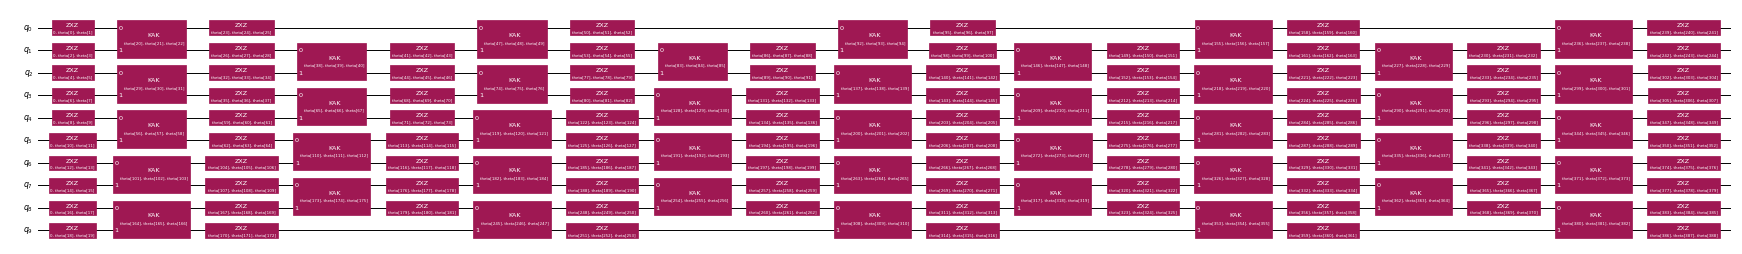

In [7]:
ansatz, initial_parameters = generate_ansatz_from_circuit(shallow_circuit, qubits_initially_zero=True)
print("number of parameters:", ansatz.num_parameters)
print("2q-depth of ansatz:  ", two_qubit_depth(ansatz.decompose()))
ansatz.draw("mpl", fold=-1, scale=0.35)

In [8]:
# Sanity check: the initial parameters reproduce the shallow Trotter circuit
shallow_mps = tensornetwork_from_circuit(shallow_circuit, simulator_settings)
init_fid = abs(compute_overlap(shallow_mps, target_mps)) ** 2
print(f"fidelity(shallow circuit, target MPS) = {init_fid:.5f}")
print(f"fidelity(ansatz(initial params), shallow) = "
      f"{abs(np.vdot(Statevector(shallow_circuit).data, Statevector(ansatz.assign_parameters(initial_parameters)).data))**2:.5f}")

fidelity(shallow circuit, target MPS) = 0.38706
fidelity(ansatz(initial params), shallow) = 1.00000


## 5. Objective and optimization

`MaximizeStateFidelity` [[10]](https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/objective.html) implements

$$
C(\vec\theta) = 1 - \left|\langle 0 | V^\dagger(\vec\theta)\,|\psi_\text{target}\rangle\right|^2 ,
$$

where $V(\vec\theta)$ is the ansatz and $|\psi_\text{target}\rangle$ is the target MPS. Its `loss_function(x)` returns `(value, gradient)`. JAX computes the gradient through the MPS contraction in quimb. So the function works directly with `scipy.optimize.minimize(..., jac=True)` and the L-BFGS-B method. The first call is slower because JAX compiles the computation.

In [9]:
objective = MaximizeStateFidelity(target_mps, ansatz, simulator_settings)

history = []
def callback(intermediate_result):
    history.append(1 - intermediate_result.fun)
    if len(history) % 10 == 0:
        print(f"iteration {len(history):3d}: fidelity = {history[-1]:.5f}")

t0 = time.perf_counter()
result = minimize(
    objective.loss_function,
    np.asarray(initial_parameters),
    method="L-BFGS-B",
    jac=True,
    options={"maxiter": 100},
    callback=callback,
)
print(f"\n{result.message}  ({result.nit} iterations, {time.perf_counter() - t0:.1f} s)")
print(f"final fidelity with target MPS: {1 - result.fun:.5f}")

iteration  10: fidelity = 0.97038
iteration  20: fidelity = 0.97959
iteration  30: fidelity = 0.98063


iteration  40: fidelity = 0.98091
iteration  50: fidelity = 0.98103



CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH  (59 iterations, 10.7 s)
final fidelity with target MPS: 0.98106


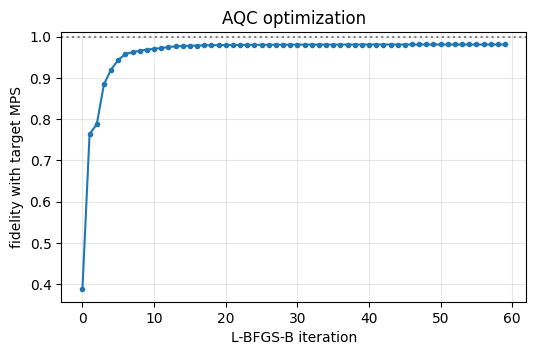

In [10]:
plt.figure(figsize=(6, 3.5))
plt.plot(range(0, len(history) + 1), [init_fid] + history, ".-")
plt.axhline(1, color="gray", ls=":")
plt.xlabel("L-BFGS-B iteration"); plt.ylabel("fidelity with target MPS")
plt.title("AQC optimization"); plt.grid(alpha=0.3); plt.show()

## 6. Compressed vs. deep circuit

We bind the optimized parameters and compare each circuit with the exact state. The AQC circuit is shallower than the 4-step Trotter circuit (two-qubit depth 27 instead of 48). The reason is that the ansatz merges the consecutive $R_{XX}R_{YY}R_{ZZ}$ gates on a bond into one two-qubit block. Its fidelity (0.981) is close to that of the 40-step circuit (0.99993).

In [11]:
aqc_circuit = ansatz.assign_parameters(result.x)

rows = [
    (f"deep Trotter ({deep_steps} steps)", deep_circuit),
    (f"shallow Trotter ({shallow_steps} steps)", shallow_circuit),
    ("AQC-compressed", aqc_circuit),
]
print(f"{'circuit':28s} {'2q-depth':>9s} {'#2q gates':>10s} {'fidelity vs exact':>18s}")
for name, qc in rows:
    qc_t = transpile(qc, basis_gates=BASIS, optimization_level=0)
    n2q = sum(1 for inst in qc_t.data if inst.operation.num_qubits == 2)
    print(f"{name:28s} {two_qubit_depth(qc_t):9d} {n2q:10d} {fidelity_with_exact(qc):18.5f}")

circuit                       2q-depth  #2q gates  fidelity vs exact
deep Trotter (40 steps)            480       2120            0.99993
shallow Trotter (4 steps)           48        212            0.38160


AQC-compressed                      27        123            0.98052


## 7. Observables with `StatevectorEstimator`

We evaluate physical observables on the compressed circuit and compare them with the exact values. The observables are:

* the local magnetizations $\langle Z_i\rangle$, which start at $\pm1$ in the Néel pattern,
* the staggered magnetization $M_s = \frac{1}{L}\sum_i (-1)^i \langle Z_i\rangle$.

We use the exact `StatevectorEstimator` primitive [[11]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator).

staggered magnetization  exact=-0.0225  AQC=-0.0256  shallow Trotter=-0.0154
max |<Z_i>| error:  AQC=0.0164  shallow Trotter=0.1548


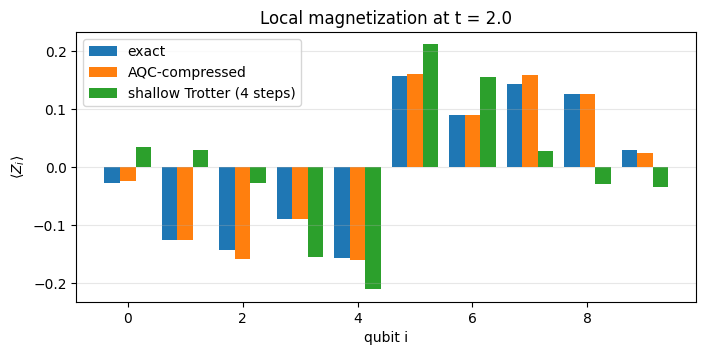

In [12]:
z_ops = [SparsePauliOp.from_sparse_list([("Z", [i], 1.0)], num_qubits=L) for i in range(L)]
stag = SparsePauliOp.from_sparse_list([("Z", [i], (-1) ** i / L) for i in range(L)], num_qubits=L)
observables = z_ops + [stag]

estimator = StatevectorEstimator()
job = estimator.run([(shallow_circuit, observables), (aqc_circuit, observables)])
ev_shallow, ev_aqc = (r.data.evs for r in job.result())

exact_sv = Statevector(exact_state)
ev_exact = np.array([exact_sv.expectation_value(o).real for o in observables])

print(f"staggered magnetization  exact={ev_exact[-1]:+.4f}  AQC={ev_aqc[-1]:+.4f}  shallow Trotter={ev_shallow[-1]:+.4f}")
print(f"max |<Z_i>| error:  AQC={np.max(abs(ev_aqc[:L]-ev_exact[:L])):.4f}  shallow Trotter={np.max(abs(ev_shallow[:L]-ev_exact[:L])):.4f}")

x = np.arange(L); w = 0.27
plt.figure(figsize=(8, 3.5))
plt.bar(x - w, ev_exact[:L], w, label="exact")
plt.bar(x, ev_aqc[:L], w, label="AQC-compressed")
plt.bar(x + w, ev_shallow[:L], w, label=f"shallow Trotter ({shallow_steps} steps)")
plt.xlabel("qubit i"); plt.ylabel(r"$\langle Z_i \rangle$"); plt.title(f"Local magnetization at t = {evolution_time}")
plt.legend(); plt.grid(alpha=0.3, axis="y"); plt.show()

## Summary

* AQC-Tensor compresses a deep circuit into a shallow parametrized circuit. It maximizes the fidelity with a **tensor-network (MPS) representation** of the target state, which is computed classically.
* The **bond dimension** $\chi$ sets the accuracy and the cost of the MPS. Low-entanglement states, such as short-time 1D dynamics, need only a small $\chi$. So the target can be computed for many more qubits than a statevector allows.
* Workflow: `QuimbSimulator` settings → `tensornetwork_from_circuit` (target MPS) → `generate_ansatz_from_circuit` (ansatz and initial parameters from a shallow circuit) → `MaximizeStateFidelity` → `scipy.optimize.minimize(..., method="L-BFGS-B", jac=True)`.
* Here a 4-step circuit was optimized to reach a fidelity of 0.981 with the exact state, compared with 0.382 before optimization. Its two-qubit depth went down from 48 to 27. The maximum error in $\langle Z_i\rangle$ dropped from 0.155 to 0.016.

In the tutorials [[1]](https://qiskit.github.io/qiskit-addon-aqc-tensor/tutorials/01_initial_state_aqc.html), [[2]](https://quantum.cloud.ibm.com/docs/en/tutorials/approximate-quantum-compilation-for-time-evolution), the AQC circuit prepares the state at an intermediate time. More shallow Trotter steps are then appended to it. Only this final part of the evolution, which is hard to simulate classically, runs on the quantum computer.

## References

1. Tutorial: Reducing circuit depth with the AQC-Tensor Qiskit addon. <https://qiskit.github.io/qiskit-addon-aqc-tensor/tutorials/01_initial_state_aqc.html>
2. IBM Quantum tutorial: Approximate quantum compilation for time evolution circuits. <https://quantum.cloud.ibm.com/docs/en/tutorials/approximate-quantum-compilation-for-time-evolution>
3. AQC-Tensor explanatory material. <https://qiskit.github.io/qiskit-addon-aqc-tensor/explanation/index.html>
4. Qiskit API reference: `PauliEvolutionGate`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.PauliEvolutionGate>
5. Qiskit API reference: `SuzukiTrotter`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.synthesis.SuzukiTrotter>
6. API reference: `qiskit_addon_aqc_tensor.simulation.quimb` (`QuimbSimulator`). <https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/simulation-quimb.html>
7. quimb API reference: `quimb.tensor.circuit.mps` (`CircuitMPS`). <https://quimb.readthedocs.io/en/latest/autoapi/quimb/tensor/circuit/mps/index.html>
8. API reference: `qiskit_addon_aqc_tensor.simulation` (`tensornetwork_from_circuit`, `compute_overlap`). <https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/simulation.html>
9. API reference: `qiskit_addon_aqc_tensor.ansatz_generation` (`generate_ansatz_from_circuit`). <https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/ansatz_generation.html>
10. API reference: `qiskit_addon_aqc_tensor.objective` (`MaximizeStateFidelity`). <https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/objective.html>
11. Qiskit API reference: `StatevectorEstimator`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator>